# 01 - Data quality and cleaning

Vietnamese property listings from Hugging Face: schema checks, missing values, duplicates and the creation of the analytical datasets.

* Data source: https://huggingface.co/datasets/tinixai/vietnam-real-estates


**Dataset information**

| Column | Meaning |
|---|---|
| `name` | Listing title |
| `description` | Listing description text |
| `property_type_name` | Property category (apartment, house, land, ...) |
| `province_name` | Province / city |
| `district_name` | District |
| `ward_name` | Ward |
| `street_name` | Street |
| `project_name` | Development project name (if any) |
| `price` | Asking price in VND (`null` if not disclosed) |
| `area` | Floor / land area in m² |
| `floor_count` | Number of floors |
| `frontage_width` | Frontage width (m) |
| `house_depth` | Depth (m) |
| `road_width` | Front road width (m) |
| `bedroom_count` | Number of bedrooms |
| `bathroom_count` | Number of bathrooms |
| `house_direction` | Facing direction |
| `balcony_direction` | Balcony facing direction |
| `published_at` | Listing publish timestamp |


**Research objectives**

Purpose: understand how asking prices of Vietnamese property listings vary by location and property type, and how reliable the data is for those comparisons.

1. **Data quality:** How complete, duplicated and valid are the listings, and which rows are kept for price analysis?
2. **Price patterns:** How do asking price and price per m² differ by province, district and property type among listings with disclosed price and area? Do the conclusions hold after removing duplicates?
3. **Associated factors:** Which attributes (area, frontage, floors, bedrooms, bathrooms) are most associated with asking price and price per m²? (Spearman on raw values, Pearson on log10.)

Assumption: every listing is treated as a property for sale, and `price` is the price the seller asks for. Results only cover listings that show a price.


## 0. SET UP


In [1]:
# uncmt if using colab
# import sys
# if "google.colab" in sys.modules:
#     !git clone <url-repo-github> /content/repo
#     %cd /content/repo/notebooks
#     !pip install -q -r ../requirements.txt

In [2]:
import os
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset

RANDOM_STATE = 42

EXPECTED_COLUMNS = [
    "name", "description", "property_type_name", "province_name", "district_name",
    "ward_name", "street_name", "project_name", "price", "area", "floor_count",
    "frontage_width", "house_depth", "road_width", "bedroom_count", "bathroom_count",
    "house_direction", "balcony_direction", "published_at",
]
CATEGORY_COLUMNS = [
    "property_type_name", "province_name", "district_name", "ward_name",
    "house_direction", "balcony_direction",
]

np.random.seed(RANDOM_STATE)

pd.options.mode.copy_on_write = True
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 12

In [3]:
parquet_file = "../data/raw/vietnam_real_estates.parquet"
if os.path.exists(parquet_file):
    print("Reading dataset...")
    df = pd.read_parquet(parquet_file)
else:
    print("Downloading dataset...")
    ds = load_dataset("tinixai/vietnam-real-estates", cache_dir="../data/raw")
    df = ds["train"].to_pandas()

    df.to_parquet(parquet_file, index=False)
print("Rows, columns:", df.shape)

Reading dataset...
Rows, columns: (3500744, 19)


In [4]:
missing = [c for c in EXPECTED_COLUMNS if c not in df.columns]
extra = [c for c in df.columns if c not in EXPECTED_COLUMNS]
assert not missing, f"Missing columns: {missing}"
assert not extra, f"Unexpected columns: {extra}"
print(f"Schema OK: {len(EXPECTED_COLUMNS)} expected columns present.")

Schema OK: 19 expected columns present.


## 1. DATA CLEANING

Conservative cleaning: flag issues, keep all rows in `df`, and build `df_priced` as a separate analytical subset.


### 1.1. Initial data inspection


In [5]:
print("Shape:", df.shape)
print(df.dtypes)
display(df.head())

Shape: (3500744, 19)
name                   object
description            object
property_type_name     object
province_name          object
district_name          object
ward_name              object
street_name            object
project_name           object
price                 float64
area                  float64
floor_count           float64
frontage_width        float64
house_depth           float64
road_width            float64
bedroom_count         float64
bathroom_count        float64
house_direction        object
balcony_direction      object
published_at           object
dtype: object


,name,description,property_type_name,province_name,district_name,ward_name,street_name,project_name,price,area,floor_count,frontage_width,house_depth,road_width,bedroom_count,bathroom_count,house_direction,balcony_direction,published_at
0,"Bán nhanh nhà 6 tầng thang máy, ngoạ long cầu ...","- Vị trí siêu đẹp ô tô đỗ cổng, khu vực đang p...",Nhà,Hà Nội,Bắc Từ Liêm,Phúc Diễn,Ngọa Long,None,7.450000e+09,37.0,NaN,NaN,NaN,NaN,4.0,5.0,None,None,2025-06-01T05:12:56.941000
1,Bán gấp nhà mặt tiền 4 tầng khu phân lô Tạ Qua...,Nhà 4 tầng mặt tiền KDC Tạ Quang Bửu P5 Q8. - ...,Nhà,Hồ Chí Minh,8,5,Tạ Quang Bửu,None,9.100000e+09,48.0,4.0,4.0,NaN,NaN,3.0,3.0,None,None,2025-06-06T04:37:25.903000
2,"Bán biệt thự 300m2 gần sân bóng Bình Minh, đườ...",Bán biệt thự Bình Minh diện tích hơn 300 mét v...,Biệt thự/Nhà liền kề,Vĩnh Long,Bình Minh,None,None,None,2.000000e+10,300.0,NaN,NaN,NaN,NaN,NaN,NaN,None,None,2025-06-15T18:58:07.455000
3,"Cần bán căn hộ CC Thái An, Nguyễn Văn Quá, Q12...","Chung cư Thái An đường Nguyễn Văn Quá, Đông Hư...",Căn hộ chung cư,Hồ Chí Minh,12,Đông Hưng Thuận,Nguyễn Văn Quá,Thái An Apartment,1.300000e+09,44.0,NaN,NaN,NaN,NaN,1.0,1.0,None,None,2025-06-17T05:32:15.491000
4,"MTKD p.Tân Thành, Tân Phú, dt 4x15m sẵn hợp đồ...","MTKD p.Tân Thành, Tân Phú, dt 4x15m sẵn hợp đồ...",Nhà,Hồ Chí Minh,Tân Phú,Tân Thành,Nguyễn Hậu,None,9.000000e+09,60.0,NaN,NaN,NaN,NaN,2.0,3.0,None,None,2025-06-06T04:06:17.378000


In [6]:
def memory_gb(frame: pd.DataFrame) -> float:
    return frame.memory_usage(deep=True).sum() / (1024 ** 3)

print(f"Memory before category conversion: {memory_gb(df):.3f} GB")

for col in CATEGORY_COLUMNS:
    df[col] = df[col].astype("category")

print(f"Memory after category conversion: {memory_gb(df):.3f} GB")

Memory before category conversion: 6.920 GB
Memory after category conversion: 5.506 GB


### 1.2. Missing value analysis

,n_missing,pct
name,0,0.000000
province_name,0,0.000000
published_at,0,0.000000
description,0,0.000000
property_type_name,0,0.000000
area,4,0.000114
district_name,101933,2.911752
price,218494,6.241359
ward_name,496716,14.188870
street_name,1376860,39.330497


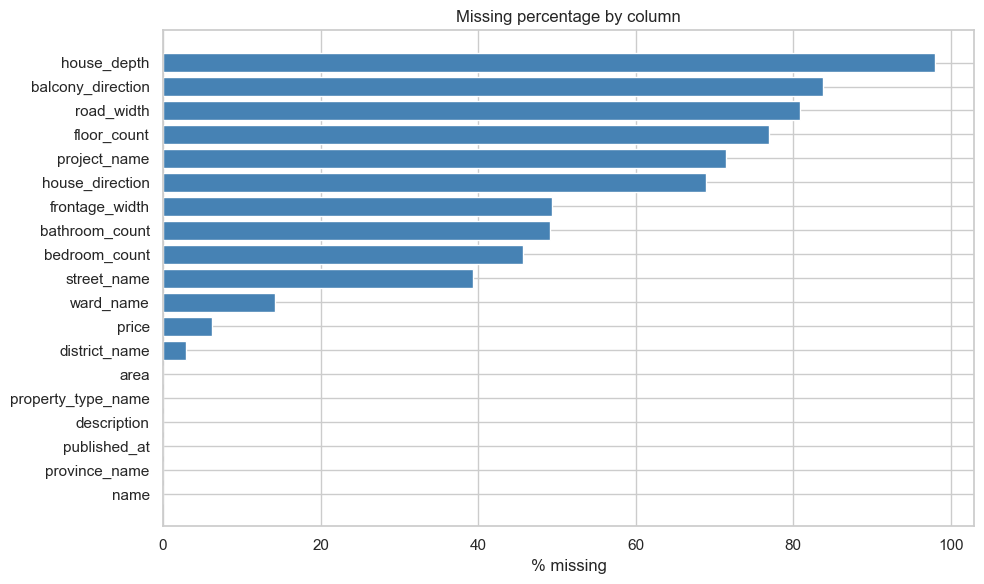

In [7]:
miss = df.isna().sum().rename("n_missing").to_frame()
miss["pct"] = 100 * miss["n_missing"] / len(df)
miss = miss.sort_values("pct", ascending=True)
display(miss)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(miss.index.astype(str), miss["pct"], color="steelblue")
ax.set_xlabel("% missing")
ax.set_title("Missing percentage by column")
plt.tight_layout()
plt.show()

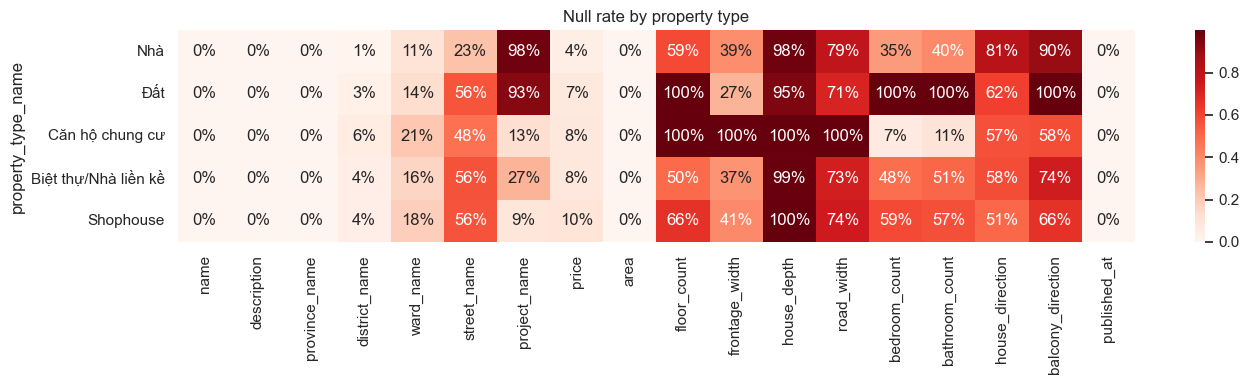

In [8]:
type_order = df["property_type_name"].value_counts().index
miss_by_type = (
    df.drop(columns="property_type_name").isna()
    .groupby(df["property_type_name"], observed=True).mean()
    .reindex(type_order)
)
fig, ax = plt.subplots(figsize=(14, 4))
sns.heatmap(miss_by_type, annot=True, fmt=".0%", cmap="Reds", ax=ax)
ax.set_title("Null rate by property type")
plt.tight_layout()
plt.show()

Listings without a valid price (price missing or ≤ 0) are excluded from `df_priced`.

In [9]:
print("price = 0:", int((df["price"] == 0).sum()))
print("price < 0:", int((df["price"] < 0).sum()))
print("area <= 0:", int((df["area"] <= 0).sum()))
neg_cols = ["floor_count", "bedroom_count", "bathroom_count"]
display((df[neg_cols] < 0).sum().rename("count_negative").to_frame())

price = 0: 57320
price < 0: 0
area <= 0: 0


,count_negative
floor_count,0
bedroom_count,0
bathroom_count,0


In [10]:
excluded = ~(df["price"].gt(0) & df["area"].gt(0))
print(f"Share of listings excluded from df_priced: {excluded.mean():.1%}")


def excluded_rate(by):
    t = excluded.groupby(by, observed=True).agg(n="size", excluded_rate="mean")
    return t


fmt = {"excluded_rate": "{:.1%}"}
display(excluded_rate(df["property_type_name"]).sort_values("n", ascending=False).style.format(fmt))
display(excluded_rate(df["province_name"]).sort_values("n", ascending=False).head(15).style.format(fmt))

Share of listings excluded from df_priced: 7.9%


,n,excluded_rate
property_type_name,,
Nhà,1575536,5.2%
Đất,832766,8.8%
Căn hộ chung cư,762800,11.1%
Biệt thự/Nhà liền kề,269782,10.5%
Shophouse,59860,13.6%


,n,excluded_rate
province_name,,
Hồ Chí Minh,1357526,5.8%
Hà Nội,1140542,9.2%
Đà Nẵng,185973,9.7%
Bình Dương,150377,7.6%
Khánh Hòa,98377,4.1%
Hải Phòng,72788,9.1%
Hưng Yên,65223,12.3%
Đồng Nai,59543,7.5%
Long An,47125,8.8%


- Missing `project_name` often means the listing is not in a named project.
- Rows with missing values are retained in the dataset.
- Listings without a valid price are excluded later from the price analysis.
- The excluded listings are spread across property types and provinces, with no group dominating.


### 1.3. Data type validation and geography / direction checks


In [11]:
numeric_cols = [
    "price", "area", "floor_count", "frontage_width", "house_depth",
    "road_width", "bedroom_count", "bathroom_count",
]
# datetime
df["published_at"] = pd.to_datetime(df["published_at"], errors="coerce")
print("published_at parse nulls:", int(df["published_at"].isna().sum()))
print("published_at min/max:", df["published_at"].min(), df["published_at"].max())

published_at parse nulls: 22024
published_at min/max: 2025-06-01 00:01:38.762000 2026-03-30 23:59:56.217000


In [12]:
print("province nunique:", df["province_name"].nunique(dropna=False))
print("district nunique:", df["district_name"].nunique(dropna=False))
dist_prov = (
    df.dropna(subset=["district_name"])
    .groupby("district_name", observed=True)["province_name"]
    .nunique()
)
print("district_name values spanning >1 province:", int((dist_prov > 1).sum()))

province nunique: 63
district nunique: 627
district_name values spanning >1 province: 15


In [13]:
display(df["house_direction"].value_counts(dropna=False))
display(df["balcony_direction"].value_counts(dropna=False))

house_direction
NaN                                2414214
Đông Nam                            145317
Nam                                 118194
Đông                                105773
Đông - Nam                          100556
Tây Bắc                              99547
Đông Bắc                             92433
Bắc                                  83539
Tây Nam                              79100
Tây - Bắc                            73043
Tây                                  70330
Đông - Bắc                           64063
Tây - Nam                            54599
Đông, Nam                                5
Đông, Bắc                                5
Tây, Đông Bắc, Tây Nam, Tây Bắc          4
Đông, Đông Nam, Nam, Bắc                 4
Đông Nam, Tây Bắc                        3
Bắc, Tây                                 2
Đông, Đông Nam, Bắc                      1
Đông, Tây Nam                            1
Đông, Tây                                1
Đông Nam, Đông Bắc                    

balcony_direction
NaN                                2933342
Đông Nam                             85314
Đông - Nam                           78628
Nam                                  61650
Đông                                 45675
Đông Bắc                             44389
Tây Bắc                              40810
Bắc                                  40241
Đông - Bắc                           39020
Tây Nam                              35939
Tây - Bắc                            35747
Tây - Nam                            31179
Tây                                  28801
Đông, Đông Nam, Nam, Bắc                 4
Đông - Bắc, Đông - Nam                   2
Tây, Đông Bắc, Tây Nam, Tây Bắc          2
Tây - Bắc, Đông - Nam                    1
Name: count, dtype: int64

### 1.4. Cleaning and analytical dataset creation

One column is added to `df` (`published_at` was already parsed as datetime in 1.3):

| Column | Definition |
|---|---|
| `is_dup` | Duplicate: same normalized name, province, district, ward, area and price as an earlier row |

`df_priced` removes duplicates, keeps listings with `price > 0` and `area > 0`

In [14]:
df_priced = df[df["price"].gt(0) & df["area"].gt(0)]

n0 = len(df)
n_priced = len(df_priced)
print(f"df: {n0:,} rows")
print(f"df_priced (price > 0 and area > 0): {n_priced:,} (excluded {n0 - n_priced:,}, {(n0 - n_priced) / n0:.2%})")

df: 3,500,744 rows
df_priced (price > 0 and area > 0): 3,224,930 (excluded 275,814, 7.88%)


#### Duplicates and price range

Duplicates are removed from df_priced

In [15]:
def normalize_text(series: pd.Series) -> pd.Series:
    """Lowercase, strip accents, map Vietnamese đ->d, collapse whitespace."""
    s = series.fillna("").astype(str).str.lower()
    s = s.map(lambda x: unicodedata.normalize("NFKD", x))
    s = s.map(lambda x: "".join(ch for ch in x if not unicodedata.combining(ch)))
    s = s.str.replace("đ", "d", regex=False)
    return s.str.replace(r"\s+", " ", regex=True).str.strip()

In [16]:
# Duplicates: same normalized text (name, province, district, ward) and same area and price
dup_check = pd.DataFrame({
    "name": normalize_text(df["name"].astype("string")),
    "province_name": normalize_text(df["province_name"].astype("string")),
    "district_name": normalize_text(df["district_name"].astype("string")),
    "ward_name": normalize_text(df["ward_name"].astype("string")),
    "area": df["area"],
    "price": df["price"],
})
df["is_dup"] = dup_check.duplicated(keep="first")

n_dup = int(df["is_dup"].sum())
print(f"Duplicates (keep=first): {n_dup:,} ({n_dup / len(df):.2%})")

combo_counts = dup_check.value_counts(dropna=False)
top_dups = combo_counts[combo_counts > 1].head(10)

print("10 most repeated listings")
with pd.option_context("display.max_colwidth", None):
    display(top_dups.reset_index(name="times_repeated"))

Duplicates (keep=first): 865,362 (24.72%)
10 most repeated listings


,name,province_name,district_name,ward_name,area,price,times_repeated
0,xuat canh ban gap - ban nha le thanh ton 42.4m2 4 tang - 15.5 ty,ho chi minh,1,ben nghe,43.0,1.550000e+10,121
1,xuat canh ban gap - ban nha phung van cung 30.1m2 3 tang - 7.98 ty,ho chi minh,phu nhuan,7,31.0,7.980000e+09,81
2,"chu ban can cityland center hills phuong 7, go vap. nha co thang may",ho chi minh,go vap,,100.0,2.100000e+10,79
3,xuat canh ban gap - ban biet thu thach thi thanh 233m2 3 tang - 125 ty,ho chi minh,1,tan dinh,233.0,1.250000e+11,75
4,xuat canh ban gap - ban nha an binh 83m2 5 tang - 20 ty,ho chi minh,5,5,83.0,2.000000e+10,68
5,"can ban nha truoc cong vien khu cityland center hill, tran thi nghi, phuong 7, go vap",ho chi minh,go vap,,100.0,1.750000e+10,68
6,xuat canh ban gap - ban nha nguyen dinh chieu 64.9m2 3 tang - 29 ty,ho chi minh,1,da kao,65.0,2.900000e+10,67
7,xuat canh ban gap - ban nha nguyen phi khanh 75.59m2 3 tang - 20.999 ty,ho chi minh,1,tan dinh,76.0,2.100000e+10,66
8,xuat canh ban gap - ban nha tran quy khoach 114.27m2 3 tang - 32 ty,ho chi minh,1,tan dinh,115.0,3.200000e+10,62
9,xuat canh ban gap - ban nha tran hung dao 13m2 4 tang - 4.48 ty,ho chi minh,1,ben thanh,13.0,4.480000e+09,60


In [17]:
# remove duplicate
df_priced = df_priced[~df.loc[df_priced.index, "is_dup"]]
print(f"df_priced after removing duplicates: {len(df_priced):,} rows")

df_priced after removing duplicates: 2,415,372 rows


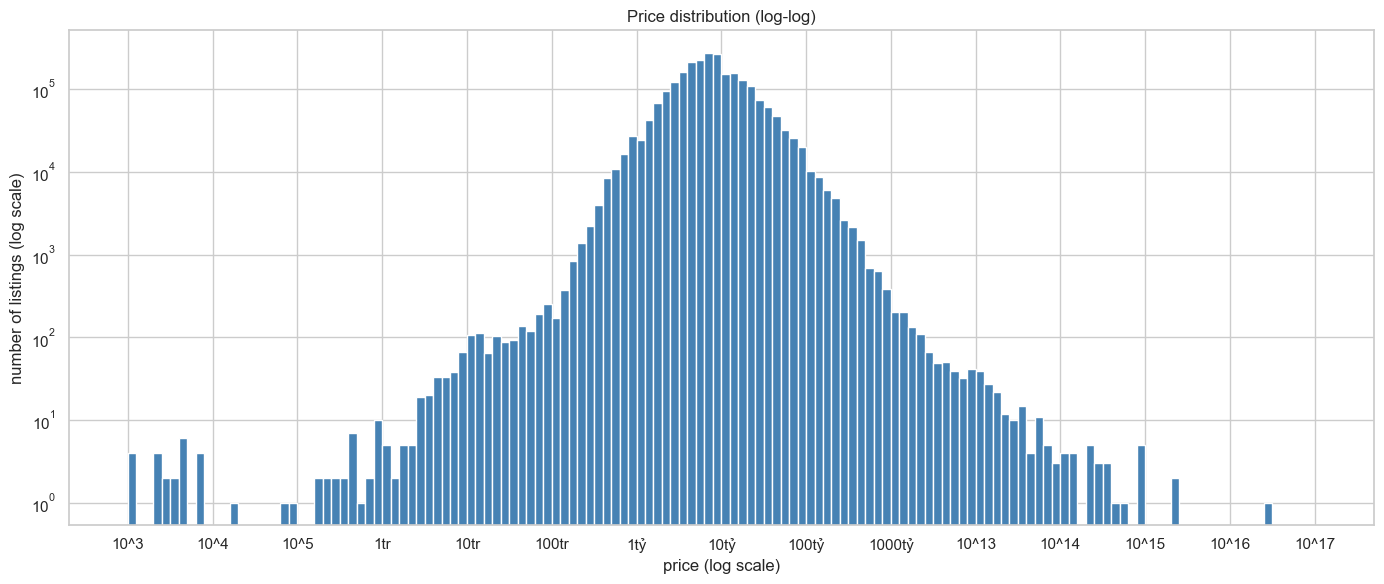

10 lowest prices:


,name,province_name,price,area
1785170,"Chủ nhà ""thả vườn"" 1400m2 đất tại Suối Hiệp, Khánh Hòa",Khánh Hòa,1000.0,1400.0
2009148,"Đất vàng Lương Sơn, 8227m² view núi, sẵn nhà, giá hời chỉ hơn 1 triệu/m²",Hòa Bình,1000.0,8227.0
3113728,"Đất hiếm đẹp, ngay trung tâm Thanh Thuỷ, cạnh siêu thị, ngân hàng",Phú Thọ,1000.0,108.0
3181512,"Nhà bán binh mỹ, Huyên cu chi dt: 4 x 13 giá 1.350 triêu lh:",Hồ Chí Minh,1000.0,96.0
3248428,"CĂN HỘ TRUNG TÂM ĐÀ NẴNG VIEW SÔNG GIÁ CHỈ TỪ 1,6 TỶ",Đà Nẵng,2000.0,45.0
3305543,"Duy nhất căn 1Br+ Áp Góc view Đại Lộ Hoa giá 1,643 tỷ tầng 06 căn Đẹp",Hà Nam,2000.0,46.6
3410161,BÁN CĂN 1PN XH1 VCN PHƯỚC LONG ĐẸP VÀO Ở NGAY SỔ SẴN 1.780 TỶ,Khánh Hòa,2000.0,42.0
3479276,Bán lô đất KDC Bến Lội giá ngộp,Bình Thuận,2000.0,100.0
3115499,Bán Tập Thể Thuốc Lá Thanh Xuân - 60m2 - 2PN 2WC Full nội thất - Giá 3.25 tỷ,Hà Nội,3000.0,65.0
3120520,CHCC Botanica Premier cần bán officetel. LH em qua: call/zalo,Hồ Chí Minh,3000.0,40.0


10 highest prices:


,name,province_name,price,area
2920301,Chủ cần bán đất dự án khu thương mại dịch vụ. và nhà ở,Đồng Nai,2.659719e+16,71884.3
2261346,"tòa nhà văn phòng mặt phố quận đống đa 410m x 10 tầng mt 13,5m hầm rộng + thang máy vị trí đắc địa!",Hà Nội,2.424000e+15,410.0
1628196,"Vị trí ""VÀNG"" - Nhà mặt phố Lý Thường Kiệt . DT 734m2, MT 30m, XD 12 tầng +4 hầm",Hà Nội,2.250000e+15,734.0
1701665,"Đất View Sông Sài Gòn PTDA Resort Villas Nghỉ Dưỡng Long Phước, Quận 9 (Tp. Thủ Đức) P. Long Phước",Hồ Chí Minh,1.000000e+15,47000.0
3296298,Duy nhất 1 Căn hộ view sông có sân vườn tại Đà Nẵng giá 60tr/m2 1,Đà Nẵng,9.999100e+14,999999.0
3448840,"Căn đẹp nhất dự án mặt sông tại Đà Nẵng , có sân vườn giá 60tr/m2",Đà Nẵng,9.999100e+14,999999.0
2040553,"Đất nền ven sông Cần Thơ, view mát mẻ, liền kề Phi Yến",Cần Thơ,9.200000e+14,244.8
20590,"Bán 7105m2 đất, hơn 100m mặt đường gần Vincom Dĩ An, đường Dt743c. Giá 124 tỷ",Bình Dương,8.810200e+14,7105.0
163378,"bán nhanh nhà Quang Trung, La Khê , Hà Đông, Hà Nội",Hà Nội,5.950000e+14,22.0
2171711,"Bán lô đất 3 hecta full thổ cư ngang 150m View Sông vị trí đẹp,mặt tiền đường Tam Thôn Hiệp,Cần Giờ",Hồ Chí Minh,4.490550e+14,29937000.0


In [18]:
# Price histogram, log10 price on x and log scale on y, so both tails are visible
log_price = np.log10(df_priced["price"])
lo, hi = np.floor(log_price.min()), np.ceil(log_price.max())

fig, ax = plt.subplots(figsize=(14, 6))
ax.hist(log_price, bins=np.arange(lo, hi + 0.1, 0.1), color="steelblue")
ax.set_yscale("log")

names = {6: "1tr", 7: "10tr", 8: "100tr", 9: "1tỷ", 10: "10tỷ", 11: "100tỷ", 12: "1000tỷ"}
ticks = np.arange(lo, hi + 1)
ax.set_xticks(ticks)
ax.set_xticklabels([names.get(int(k), f"10^{int(k)}") for k in ticks])
ax.set_xlabel("price (log scale)")
ax.set_ylabel("number of listings (log scale)")
ax.set_title("Price distribution (log-log)")
plt.tight_layout()
plt.show()

# the actual extreme listings
cols_show = ["name", "province_name", "price", "area"]
with pd.option_context("display.max_colwidth", None):
    print("10 lowest prices:")
    display(df_priced.nsmallest(10, "price")[cols_show])
    print("10 highest prices:")
    display(df_priced.nlargest(10, "price")[cols_show])


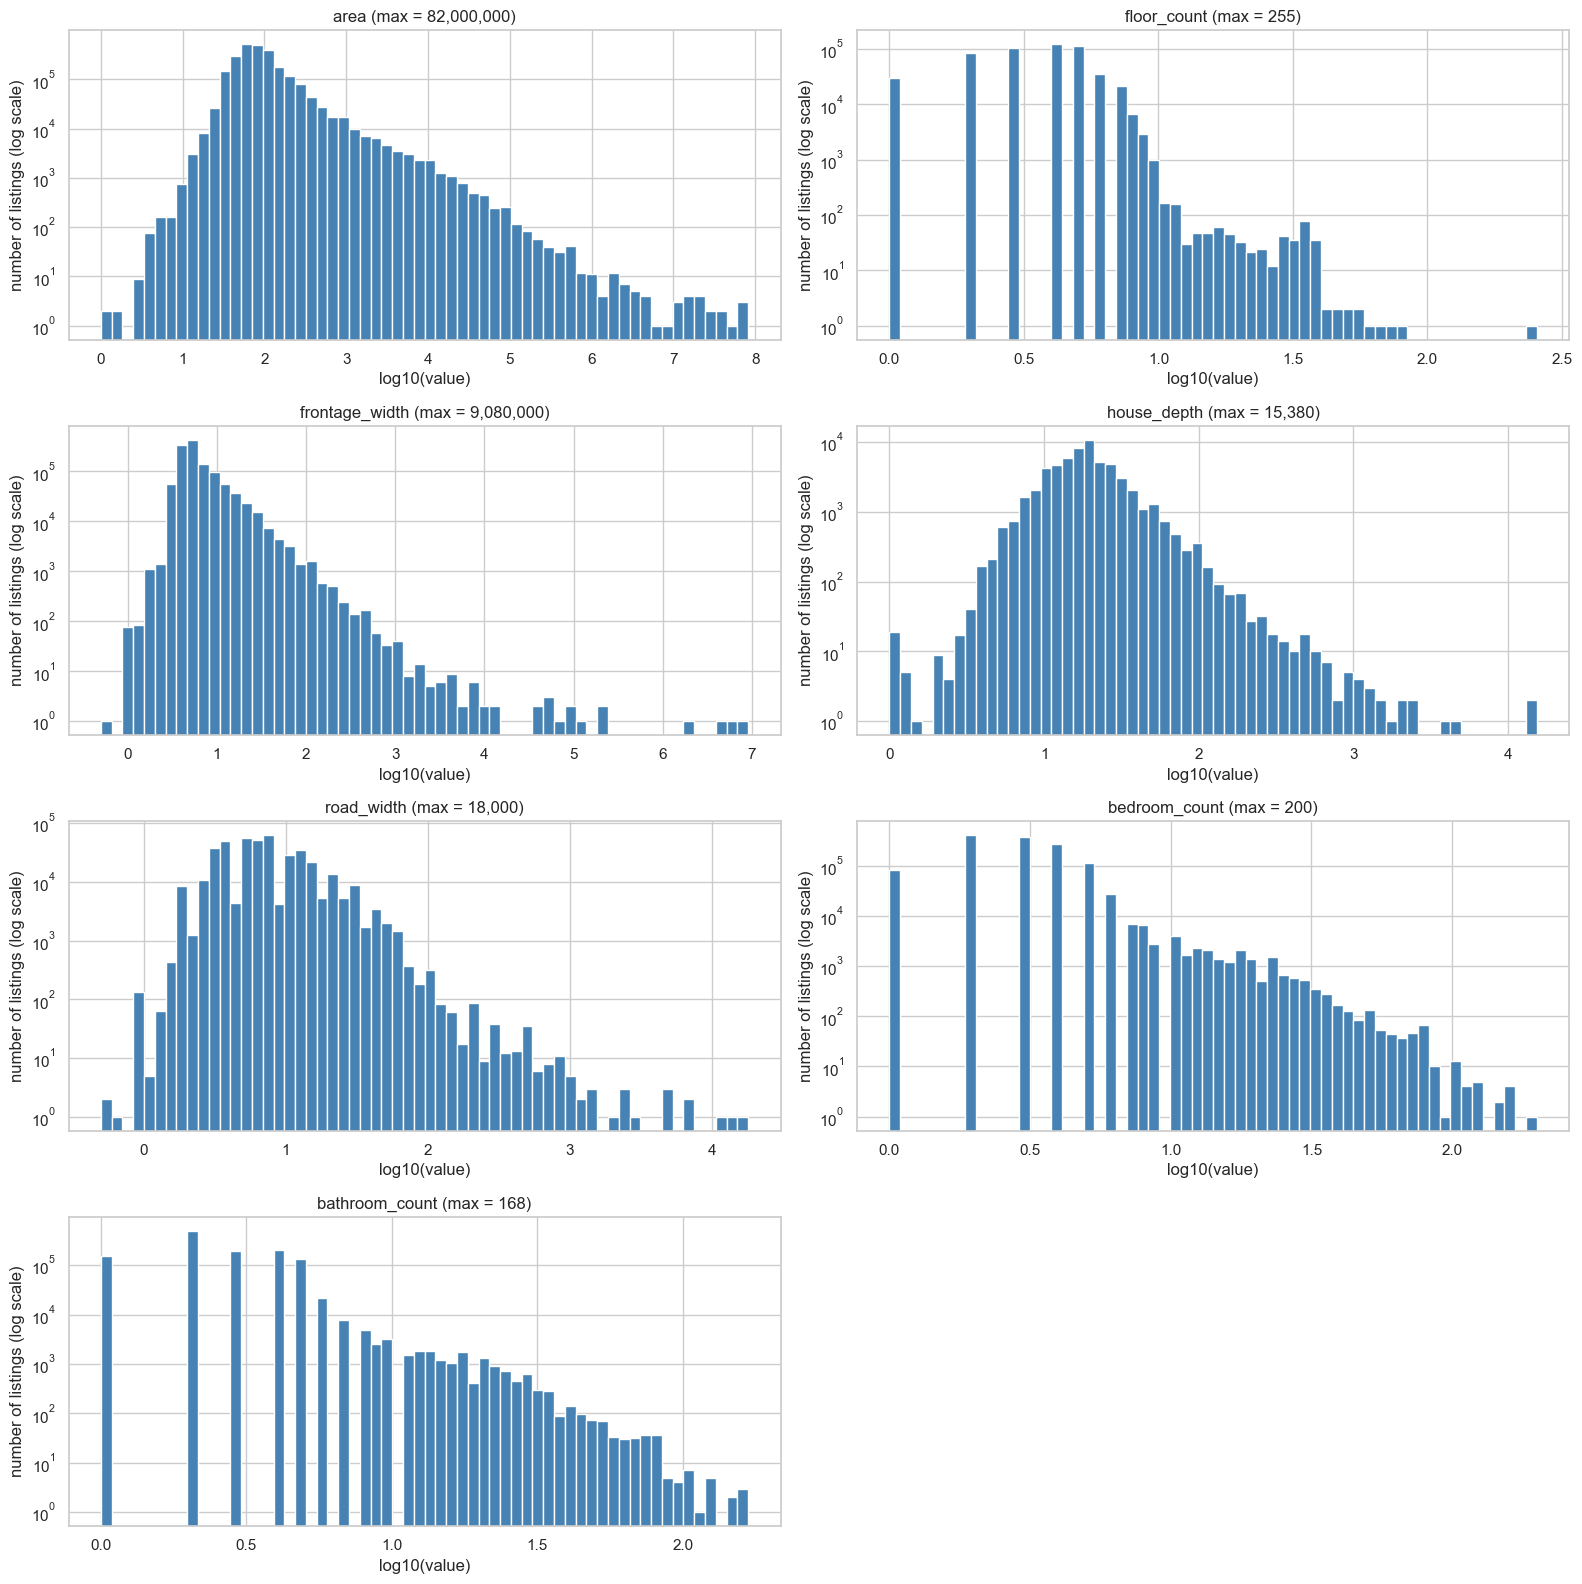

In [19]:
cols = ["area", "floor_count", "frontage_width", "house_depth", "road_width", "bedroom_count", "bathroom_count"]

fig, axes = plt.subplots(4, 2, figsize=(16, 16))
for ax, col in zip(axes.flat, cols):
    values = df_priced[col].dropna()
    ax.hist(np.log10(values), bins=60, color="steelblue")
    ax.set_yscale("log")
    ax.set_title(f"{col} (max = {values.max():,.0f})")
    ax.set_xlabel("log10(value)")
    ax.set_ylabel("number of listings (log scale)")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

In [20]:
# Count how many rows fall outside candidate price ranges (nothing is removed here)
lo, hi = 1e8, 1e12
outside = ~df_priced["price"].between(lo, hi)
print(f"price in [{lo:.0e}, {hi:.0e}]: removes {outside.sum():,} rows ({outside.mean():.3%})")

price in [1e+08, 1e+12]: removes 2,574 rows (0.107%)


In [21]:
n_before = len(df_priced)
df_priced = df_priced[df_priced["price"].between(lo, hi)]
print(f"Removed {n_before - len(df_priced):,} rows with price outside [1e8, 1e12]; {len(df_priced):,} rows left")

Removed 2,574 rows with price outside [1e8, 1e12]; 2,412,798 rows left


In [22]:
n2_before = len(df_priced)
df_priced = df_priced[df_priced["published_at"].notna()]
print(f"Removed {n2_before - len(df_priced):,} rows with no publish day; {len(df_priced):,} rows left")

Removed 14,455 rows with no publish day; 2,398,343 rows left


In [23]:
LIMITS = {
    "area": (10, 100_000),
    "floor_count": (1, 50),
    "frontage_width": (1, 200),
    "house_depth": (2, 500),
    "road_width": (1, 100),
    "bedroom_count": (1, 50),
    "bathroom_count": (1, 50),
}

for col, (low, high) in LIMITS.items():
    outside = df_priced[col].notna() & ~df_priced[col].between(low, high)
    print(f"{col}: {outside.sum():,} values outside [{low}, {high}]")

n_before = len(df_priced)
df_priced = df_priced[df_priced["area"].between(*LIMITS["area"])]

for col, (low, high) in LIMITS.items():
    if col != "area":
        df_priced[col] = df_priced[col].where(df_priced[col].between(low, high))

print(f"Removed {n_before - len(df_priced):,} rows with invalid area; {len(df_priced):,} rows left")

area: 876 values outside [10, 100000]
floor_count: 8 values outside [1, 50]
frontage_width: 761 values outside [1, 200]
house_depth: 70 values outside [2, 500]
road_width: 424 values outside [1, 100]
bedroom_count: 340 values outside [1, 50]
bathroom_count: 267 values outside [1, 50]
Removed 876 rows with invalid area; 2,397,467 rows left


### 1.5. Save analytical datasets

In [24]:
df_priced.to_parquet("../data/processed/priced_listings.parquet", index=False)
print(f"Saved {len(df_priced):,} rows -> priced_listings.parquet")

Saved 2,397,467 rows -> priced_listings.parquet
